In [1]:
!pip install finlens

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 18.1 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


# IMPORT THƯ VIỆN VÀ KÉO DỮ LIỆU TỪ FINLENS VỀ BẰNG API

In [2]:
from finlens import client
cli = client(api_key="b739e2f510e5786baa19a85d70e778160c63cf0071fdf4064148f1e5222b75a0")

In [3]:
help(cli.financials.statement)

Help on method statement in module finlens.namespaces:

statement(
    symbols: 'SymbolsArg',
    *,
    kind: 'StatementKind' = 'balance_sheet',
    period: 'StatementPeriod' = 'annual',
    start_year: 'YearArg' = None,
    end_year: 'YearArg' = None,
    quarters: 'QuartersArg' = None,
    refresh: 'bool' = False,
    on_error: 'OnError' = 'warn'
) -> 'DataFrame' method of finlens.namespaces.Financials instance
    Báo cáo tài chính theo khoản mục cho một hoặc nhiều mã.

    Một dòng cho mỗi khoản mục của mỗi kỳ (**long format**), kèm ba cột cây
    `parent_id` / `level` / `order_index` để dựng lại cấu trúc báo cáo ngay
    trên frame — không phải gọi thêm `line_items()` rồi tự ghép. Cha/con là
    `parent_id`; đọc Notes trước khi dùng `level`.

    Nhiều mã đi trong **một** request HTTP, và **được phép trộn nhiều loại
    doanh nghiệp**: `"HPG,VCB,SSI"` trả về ba cây khác nhau trong cùng một
    frame, phân biệt bằng cột `company_type`. Đó là mặc định chứ không phải
    một trường 

In [7]:
import finlens
# Tăng deadline lên 600 giây để hệ thống có đủ thời gian tự động giãn cách tải 100 mã cổ phiếu
cli = finlens.client(api_key="33345322ab0b54ed5d99c88f4af4718534dec27d30f685440e7a1eaf440e84fb", deadline=600)
balance = cli.financials.statement(
symbols=['AAA','ACB','AGG','ANV','ASM','BCG','BCM','BID','BMP','BVH','BWE','CII','CMG','CRE','CTD','CTG','CTR','DBC','DCM','DGC','DGW','DHC','DIG','DPM','DXG','DXS','EIB','FPT','FRT','FTS','GAS','GEG','GEX','GMD','GVR','HCM','HDB','HDC','HDG','HHV','HPG','HSG','HT1','IMP','KBC','KDC','KDH','KOS','LPB','MBB','MSB','MSN','MWG','NKG','NLG','NT2','NVL','OCB','PAN','PC1','PDR','PHR','PLX','PNJ','POW','PPC','PTB','PVD','PVT','REE','SAB','SAM','SBT','SCR','SCS','SHB','SJS','SSB','SSI','STB','SZC','TCB','TCH','TMS','TPB','VCB','VCG','VCI','VHC','VHM','VIB','VIC','VIX','VJC','VND','VNM','VPB','VPI','VRE','VSH'],
kind='balance_sheet',
period='annual',
start_year=2020,
end_year=2025,
)

balance.head()

/usr/lib/python3.13/asyncio/events.py:89: DataQualityWarning: [PERIOD_PARTIAL] Dải năm bạn yêu cầu rộng hơn dải thực sự có dữ liệu của các mã sau: BCG (2020-2024). Phần nằm ngoài rỗng vì nguồn không có, không phải vì doanh nghiệp không công bố báo cáo. Tra dải thật ở `/reporting/periods`.
  self._context.run(self._callback, *self._args)


,symbol,company_type,kind,year,quarter,period_label,item_id,line_item,parent_id,level,order_index,value
0,AAA,CT,balance_sheet,2025,0,2025,1,TÀI SẢN,<NA>,1,0,NaN
1,AAA,CT,balance_sheet,2025,0,2025,2,A. Tài sản lưu động và đầu tư ngắn hạn,1,2,1,4.532817e+12
2,AAA,CT,balance_sheet,2025,0,2025,3,I. Tiền và các khoản tương đương tiền,2,3,2,1.617746e+12
3,AAA,CT,balance_sheet,2025,0,2025,4,1. Tiền,3,4,3,1.182944e+12
4,AAA,CT,balance_sheet,2025,0,2025,5,2. Các khoản tương đương tiền,3,4,4,4.348019e+11


In [12]:
import finlens
cli = finlens.client(api_key="33345322ab0b54ed5d99c88f4af4718534dec27d30f685440e7a1eaf440e84fb", deadline=800)
income = cli.financials.statement(
symbols=['AAA','ACB','AGG','ANV','ASM','BCG','BCM','BID','BMP','BVH','BWE','CII','CMG','CRE','CTD','CTG','CTR','DBC','DCM','DGC','DGW','DHC','DIG','DPM','DXG','DXS','EIB','FPT','FRT','FTS','GAS','GEG','GEX','GMD','GVR','HCM','HDB','HDC','HDG','HHV','HPG','HSG','HT1','IMP','KBC','KDC','KDH','KOS','LPB','MBB','MSB','MSN','MWG','NKG','NLG','NT2','NVL','OCB','PAN','PC1','PDR','PHR','PLX','PNJ','POW','PPC','PTB','PVD','PVT','REE','SAB','SAM','SBT','SCR','SCS','SHB','SJS','SSB','SSI','STB','SZC','TCB','TCH','TMS','TPB','VCB','VCG','VCI','VHC','VHM','VIB','VIC','VIX','VJC','VND','VNM','VPB','VPI','VRE','VSH'],
kind='income_statement',
period='annual',
start_year=2020,
end_year=2025,
)
income.head()

/usr/lib/python3.13/asyncio/events.py:89: DataQualityWarning: [PERIOD_PARTIAL] Dải năm bạn yêu cầu rộng hơn dải thực sự có dữ liệu của các mã sau: BCG (2020-2024). Phần nằm ngoài rỗng vì nguồn không có, không phải vì doanh nghiệp không công bố báo cáo. Tra dải thật ở `/reporting/periods`.
  self._context.run(self._callback, *self._args)


,symbol,company_type,kind,year,quarter,period_label,item_id,line_item,parent_id,level,order_index,value
0,AAA,CT,income_statement,2025,0,2025,1,1. Tổng doanh thu hoạt động kinh doanh,<NA>,1,0,1.073378e+13
1,AAA,CT,income_statement,2025,0,2025,2,2. Các khoản giảm trừ doanh thu,<NA>,1,1,5.632074e+09
2,AAA,CT,income_statement,2025,0,2025,3,3. Doanh thu thuần (1)-(2),<NA>,1,2,1.072815e+13
3,AAA,CT,income_statement,2025,0,2025,4,4. Giá vốn hàng bán,<NA>,1,3,9.235314e+12
4,AAA,CT,income_statement,2025,0,2025,5,5. Lợi nhuận gộp (3)-(4),<NA>,1,4,1.492833e+12


In [28]:
import finlens
cli = finlens.client(api_key="33345322ab0b54ed5d99c88f4af4718534dec27d30f685440e7a1eaf440e84fb", deadline=1100)
cashflow = cli.financials.statement(
symbols=['AAA','ACB','AGG','ANV','ASM','BCG','BCM','BID','BMP','BVH',
    'BWE','CII','CMG','CRE','CTD','CTG','CTR','DBC','DCM','DGC',
    'DGW','DHC','DIG','DPM','DXG','DXS','EIB','FPT','FRT','GAS',
    'GEG','GEX','GMD','GVR','HDB','HDC','HDG','HHV','HPG','HSG',
    'HT1','IMP','KBC','KDC','KDH','KOS','LPB','MBB','MSB','MSN',
    'MWG','NKG','NLG','NT2','NVL','OCB','PAN','PC1','PDR','PHR',
    'PLX','PNJ','POW','PPC','PTB','PVD','PVT','REE','SAB','SAM',
    'SBT','SCR','SCS','SHB','SJS','SSB','STB','SZC','TCB','TCH',
    'TMS','TPB','VCB','VCG','VHC','VHM','VIB','VIC','VJC','VNM',
    'VPB','VPI','VRE','VSH'],
kind='cash_flow_direct',
period='annual',
start_year=2020,
end_year=2025,
)
cashflow.head()

,symbol,company_type,kind,year,quarter,period_label,item_id,line_item,parent_id,level,order_index,value
0,ACB,NH,cash_flow_direct,2025,0,2025,1,I. Lưu chuyển tiền từ hoạt động kinh doanh,<NA>,1,0,NaN
1,ACB,NH,cash_flow_direct,2025,0,2025,2,- Thu nhập lãi và các khoản thu nhập tương tự...,1,2,1,5.689057e+13
2,ACB,NH,cash_flow_direct,2025,0,2025,3,- Chi phí lãi và các chi phí tương tự đã trả,1,2,2,-2.992075e+13
3,ACB,NH,cash_flow_direct,2025,0,2025,4,- Thu nhập từ hoạt động dịch vụ nhận được,1,2,3,2.580073e+12
4,ACB,NH,cash_flow_direct,2025,0,2025,5,- Chênh lệch số tiền thực thu/ thực chi từ hoạ...,1,2,4,2.636825e+12


In [26]:
import pandas as pd


def pivot_financials(df):
   # Giữ lại các cột định danh và xoay bảng theo line_item
   pivoted = df.pivot_table(
       index=['symbol', 'year'],
       columns='line_item',
       values='value',
       aggfunc='first'
   ).reset_index()
   return pivoted

In [29]:
# Chuyển đổi từng bảng sang định dạng ngang
balance_wide = pivot_financials(balance)
income_wide = pivot_financials(income)
cashflow_wide = pivot_financials(cashflow)

In [30]:
# Gộp các bảng lại với nhau
merged_financials = pd.merge(balance_wide, income_wide, on=['symbol', 'year'], how='outer')
merged_financials = pd.merge(merged_financials, cashflow_wide, on=['symbol', 'year'], how='outer')

In [31]:
print("Đã gộp thành công các bảng tài chính. Kích thước bảng mới:", merged_financials.shape)
display(merged_financials.head())

Đã gộp thành công các bảng tài chính. Kích thước bảng mới: (599, 596)


line_item,symbol,year,- Cổ phiếu quỹ,- Cổ phiếu ưu đãi,- Giá trị hao mòn lũy kế,- LNST chưa phân phối kỳ này,- LNST chưa phân phối lũy kế đến cuối kỳ trước,- Nguyên giá,- Nguồn kinh phí sự nghiệp năm nay,- Nguồn kinh phí sự nghiệp năm trước,...,8. Tiền chi khác cho hoạt động kinh doanh,Lưu chuyển tiền thuần trong kỳ,Lưu chuyển tiền thuần từ hoạt động kinh doanh,Lưu chuyển tiền thuần từ hoạt động kinh doanh trước những thay đổi về tài sản và vốn lưu động,Lưu chuyển tiền thuần từ hoạt động tài chính,Lưu chuyển tiền thuần từ hoạt động đầu tư,Lưu chuyển tiền từ hoạt động tài chính,Tiền và tương đương tiền cuối kỳ,Tiền và tương đương tiền đầu kỳ,Ảnh hưởng của thay đổi tỷ giá hối đoái quy đổi ngoại tệ
0,AAA,2020,NaN,NaN,-1.232888e+12,2.547856e+11,3.139312e+11,3.478173e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AAA,2021,NaN,NaN,-1.460375e+12,3.320890e+11,3.744045e+11,3.482795e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AAA,2022,NaN,NaN,-1.706991e+12,9.327463e+10,6.284134e+11,3.706996e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAA,2023,NaN,NaN,-1.961659e+12,2.894105e+11,2.732120e+11,3.825526e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AAA,2024,NaN,NaN,-2.191462e+12,2.488399e+10,5.144277e+11,5.028006e+12,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
import numpy as np
import pandas as pd

# 1. Phân loại các doanh nghiệp theo nhóm ngành dựa trên 'company_type'
# Finlens phân loại sẵn các mã: 'NH' (Ngân hàng), 'CK' (Chứng khoán), 'CT' (Công ty thương mại, dịch vụ, sản xuất thông thường)

# Lấy danh sách các mã độc nhất và loại hình doanh nghiệp tương ứng từ dữ liệu gốc
if 'balance' in globals():
    company_sectors = balance[['symbol', 'company_type']].drop_duplicates()

    # Phân nhóm danh sách mã theo ngành
    banks = company_sectors[company_sectors['company_type'] == 'NH']['symbol'].tolist()
    securities = company_sectors[company_sectors['company_type'] == 'CK']['symbol'].tolist()
    corporates = company_sectors[company_sectors['company_type'] == 'CT']['symbol'].tolist()

    print(f"--- THỐNG KÊ PHÂN LOẠI NGÀNH ---")
    print(f"- Ngân hàng (NH) - {len(banks)} doanh nghiệp: {banks[:5]}...")
    print(f"- Chứng khoán (CK) - {len(securities)} doanh nghiệp: {securities[:5]}...")
    print(f"- Doanh nghiệp thông thường (CT) - {len(corporates)} doanh nghiệp: {corporates[:5]}...")

# 2. Đọc và làm sạch dữ liệu tài chính đã gộp (merged_financials)
if 'merged_financials' in globals():
    print("\n--- BẮT ĐẦU LÀM SẠCH DỮ LIỆU ---")
    df_clean = merged_financials.copy()

    # Chuẩn hóa kiểu dữ liệu cho 'year' về dạng số nguyên
    df_clean['year'] = pd.to_numeric(df_clean['year'], errors='coerce')
    df_clean = df_clean.dropna(subset=['year'])
    df_clean['year'] = df_clean['year'].astype(int)

    # Loại bỏ các cột hoặc dòng có quá nhiều giá trị NaN (ví dụ: dòng không có dữ liệu tài chính nào)
    # Xác định các cột số để làm sạch
    numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.difference(['year'])

    # Loại bỏ các dòng mà tất cả các khoản mục tài chính đều bị trống (NaN)
    before_rows = len(df_clean)
    df_clean = df_clean.dropna(subset=numeric_cols, how='all')
    print(f"- Đã loại bỏ {before_rows - len(df_clean)} dòng trống hoàn toàn dữ liệu số.")

    # Điền giá trị 0 cho các khoản mục tài chính bị thiếu (NaN) có thể chấp nhận được (ví dụ: doanh nghiệp không có khoản mục đó)
    df_clean[numeric_cols] = df_clean[numeric_cols].fillna(0)

    # Sắp xếp lại dữ liệu theo Mã cổ phiếu và Năm tài chính
    df_clean = df_clean.sort_values(by=['symbol', 'year']).reset_index(drop=True)

    print(f"- Kích thước dữ liệu sau khi làm sạch: {df_clean.shape}")
    display(df_clean.head())
else:
    print("Không tìm thấy biến merged_financials trong bộ nhớ. Hãy chạy các ô phía trên trước.")

--- THỐNG KÊ PHÂN LOẠI NGÀNH ---
- Ngân hàng (NH) - 17 doanh nghiệp: ['ACB', 'BID', 'CTG', 'EIB', 'HDB']...
- Chứng khoán (CK) - 6 doanh nghiệp: ['FTS', 'HCM', 'SSI', 'VCI', 'VIX']...
- Doanh nghiệp thông thường (CT) - 76 doanh nghiệp: ['AAA', 'AGG', 'ANV', 'ASM', 'BCG']...

--- BẮT ĐẦU LÀM SẠCH DỮ LIỆU ---
- Đã loại bỏ 0 dòng trống hoàn toàn dữ liệu số.
- Kích thước dữ liệu sau khi làm sạch: (599, 596)


line_item,symbol,year,- Cổ phiếu quỹ,- Cổ phiếu ưu đãi,- Giá trị hao mòn lũy kế,- LNST chưa phân phối kỳ này,- LNST chưa phân phối lũy kế đến cuối kỳ trước,- Nguyên giá,- Nguồn kinh phí sự nghiệp năm nay,- Nguồn kinh phí sự nghiệp năm trước,...,8. Tiền chi khác cho hoạt động kinh doanh,Lưu chuyển tiền thuần trong kỳ,Lưu chuyển tiền thuần từ hoạt động kinh doanh,Lưu chuyển tiền thuần từ hoạt động kinh doanh trước những thay đổi về tài sản và vốn lưu động,Lưu chuyển tiền thuần từ hoạt động tài chính,Lưu chuyển tiền thuần từ hoạt động đầu tư,Lưu chuyển tiền từ hoạt động tài chính,Tiền và tương đương tiền cuối kỳ,Tiền và tương đương tiền đầu kỳ,Ảnh hưởng của thay đổi tỷ giá hối đoái quy đổi ngoại tệ
0,AAA,2020,0.0,0.0,-1.232888e+12,2.547856e+11,3.139312e+11,3.478173e+12,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,AAA,2021,0.0,0.0,-1.460375e+12,3.320890e+11,3.744045e+11,3.482795e+12,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,AAA,2022,0.0,0.0,-1.706991e+12,9.327463e+10,6.284134e+11,3.706996e+12,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,AAA,2023,0.0,0.0,-1.961659e+12,2.894105e+11,2.732120e+11,3.825526e+12,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,AAA,2024,0.0,0.0,-2.191462e+12,2.488399e+10,5.144277e+11,5.028006e+12,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [37]:
import pandas as pd
import numpy as np

# Khởi tạo bản sao dữ liệu đã làm sạch
df_calc = df_clean.copy()

# ĐƯA LẠI CỘT 'company_type' VÀO DF_CALC BẰNG CÁCH MERGE VỚI COMPANY_SECTORS
if 'company_sectors' in globals():
    df_calc = pd.merge(df_calc, company_sectors, on='symbol', how='left')
else:
    # Nếu không có sẵn, thử lấy từ bảng balance
    if 'balance' in globals():
        sectors = balance[['symbol', 'company_type']].drop_duplicates()
        df_calc = pd.merge(df_calc, sectors, on='symbol', how='left')
    else:
        df_calc['company_type'] = 'CT' # Mặc định

# Định nghĩa hàm chia an toàn tránh lỗi chia cho 0 hoặc NaN
def safe_div(num, denom):
    return np.where((denom != 0) & (~pd.isna(denom)), num / denom, np.nan)

# --- 1. ÁNH XẠ CÁC KHOẢN MỤC TÀI CHÍNH TỪ TIẾNG VIỆT SANG TIẾNG ANH ---
mappings = {
    'Current_Assets': ['A. Tài sản lưu động và đầu tư ngắn hạn', 'TÀI SẢN NGẮN HẠN'],
    'Inventory': ['Hàng tồn kho', 'IV. Hàng tồn kho'],
    'Current_Liabilities': ['Nợ ngắn hạn', 'I. Nợ ngắn hạn'],
    'Total_Liabilities': ['Tổng nợ phải trả', 'NỢ PHẢI TRẢ'],
    'Total_Equity': ['Vốn chủ sở hữu', 'D. VỐN CHỦ SỞ HỮU', 'I. Vốn chủ sở hữu'],
    'Total_Assets': ['Tổng cộng tài sản', 'TÀI SẢN', 'TỔNG CỘNG TÀI SẢN'],
    'EBIT': ['Lợi nhuận trước thuế', 'Tổng lợi nhuận kế toán trước thuế'],
    'Interest_Expense': ['Chi phí lãi vay', 'Trong đó: Chi phí lãi vay'],
    'Net_Income': ['Lợi nhuận sau thuế thu nhập doanh nghiệp', 'Lợi nhuận sau thuế của cổ đông công ty mẹ', 'Lợi nhuận sau thuế'],
    'Revenue': ['Doanh thu thuần (1)-(2)', 'Doanh thu thuần về bán hàng và cung cấp dịch vụ', 'Doanh thu thuần'],
    'Receivables': ['Các khoản phải thu ngắn hạn', 'I. Các khoản phải thu ngắn hạn'],
    'Cost_of_Goods_Sold': ['Giá vốn hàng bán', '2. Giá vốn hàng bán'],
    'Outstanding_Shares': ['Số lượng cổ phiếu phổ thông đang lưu hành', 'Cổ phiếu phổ thông đang lưu hành']
}

# Áp dụng ánh xạ để trích xuất các cột cần thiết
for target_col, source_options in mappings.items():
    found = False
    for opt in source_options:
        if opt in df_calc.columns:
            df_calc[target_col] = pd.to_numeric(df_calc[opt], errors='coerce').fillna(0)
            found = True
            break
    if not found:
        df_calc[target_col] = 0.0

# --- 2. TÍNH TOÁN CÁC CHỈ TIÊU CƠ BẢN (CHO DOANH NGHIỆP THƯỜNG - CT) ---

# Khả năng thanh toán
df_calc['Current_Ratio'] = safe_div(df_calc['Current_Assets'], df_calc['Current_Liabilities'])
df_calc['Quick_Ratio'] = safe_div(df_calc['Current_Assets'] - df_calc['Inventory'], df_calc['Current_Liabilities'])

# Đòn bẩy tài chính
df_calc['Debt_to_Equity'] = safe_div(df_calc['Total_Liabilities'], df_calc['Total_Equity'])
df_calc['Debt_to_Asset'] = safe_div(df_calc['Total_Liabilities'], df_calc['Total_Assets'])
df_calc['TIE'] = safe_div(df_calc['EBIT'], df_calc['Interest_Expense'])

# Khả năng sinh lời
df_calc['ROE'] = safe_div(df_calc['Net_Income'], df_calc['Total_Equity'])
df_calc['ROA'] = safe_div(df_calc['Net_Income'], df_calc['Total_Assets'])
df_calc['ROS'] = safe_div(df_calc['Net_Income'], df_calc['Revenue'])
df_calc['EPS'] = safe_div(df_calc['Net_Income'], df_calc['Outstanding_Shares'])

# Hiệu quả sử dụng tài sản
df_calc['Asset_Turnover'] = safe_div(df_calc['Revenue'], df_calc['Total_Assets'])
df_calc['Inventory_Turnover'] = safe_div(df_calc['Cost_of_Goods_Sold'], df_calc['Inventory'])
df_calc['Receivables_Turnover'] = safe_div(df_calc['Revenue'], df_calc['Receivables'])

# Chu kỳ chuyển đổi tiền mặt (CCC = DIO + DSO)
dio = safe_div(365, df_calc['Inventory_Turnover'])
dso = safe_div(365, df_calc['Receivables_Turnover'])
df_calc['CCC'] = dio + dso

# --- 3. TÍNH TOÁN TĂNG TRƯỞNG (GROWTH) ---
df_calc = df_calc.sort_values(by=['symbol', 'year'])
df_calc['Prev_Revenue'] = df_calc.groupby('symbol')['Revenue'].shift(1)
df_calc['Prev_Net_Income'] = df_calc.groupby('symbol')['Net_Income'].shift(1)
df_calc['Prev_EPS'] = df_calc.groupby('symbol')['EPS'].shift(1)

df_calc['Revenue_Growth'] = safe_div(df_calc['Revenue'] - df_calc['Prev_Revenue'], df_calc['Prev_Revenue'])
df_calc['Net_Profit_Growth'] = safe_div(df_calc['Net_Income'] - df_calc['Prev_Net_Income'], df_calc['Prev_Net_Income'])
df_calc['EPS_Growth'] = safe_div(df_calc['EPS'] - df_calc['Prev_EPS'], df_calc['Prev_EPS'])

# --- 4. TÍNH TOÁN CÁC CHỈ TIÊU CHO NGÂN HÀNG (NH) ---
bank_mappings = {
    'Interest_Income': ['Thu nhập lãi và các khoản thu nhập tương tự', '1. Thu nhập lãi và các khoản thu nhập tương tự'],
    'Interest_Expense_Bank': ['Chi phí lãi và các chi phí tương tự', '2. Chi phí lãi và các chi phí tương tự'],
    'Earning_Assets': ['Cho vay khách hàng', 'III. Cho vay khách hàng'],
    'Bad_Debts': ['Nợ xấu', 'Nợ nhóm 3, 4, 5'],
    'Total_Loans': ['Cho vay khách hàng', 'III. Cho vay khách hàng'],
    'Equity_CAR': ['Vốn tự có', 'Vốn cấp 1'],
    'Risk_Weighted_Assets': ['Tổng tài sản có rủi ro'],
    'Stock_Price': ['Giá cổ phiếu', 'Giá đóng cửa']
}

for target_col, source_options in bank_mappings.items():
    found = False
    for opt in source_options:
        if opt in df_calc.columns:
            df_calc[target_col] = pd.to_numeric(df_calc[opt], errors='coerce').fillna(0)
            found = True
            break
    if not found:
        df_calc[target_col] = np.nan

# Tính chỉ số Ngân hàng
df_calc['NIM'] = safe_div(df_calc['Interest_Income'] - df_calc['Interest_Expense_Bank'], df_calc['Earning_Assets'])
df_calc['NPL'] = safe_div(df_calc['Bad_Debts'], df_calc['Total_Loans'])
df_calc['CAR'] = safe_div(df_calc['Equity_CAR'], df_calc['Risk_Weighted_Assets'])
df_calc['BVPS'] = safe_div(df_calc['Total_Equity'], df_calc['Outstanding_Shares'])
df_calc['P_B'] = safe_div(df_calc['Stock_Price'], df_calc['BVPS'])

# Điền NaN cho các chỉ số ngân hàng đối với doanh nghiệp thông thường để phân biệt rõ ràng
non_bank_mask = df_calc['company_type'] != 'NH'
df_calc.loc[non_bank_mask, ['NIM', 'NPL', 'CAR', 'P_B']] = np.nan

# --- 5. LỌC RA BẢNG KẾT QUẢ CUỐI CÙNG ---
final_cols = [
    'symbol', 'year', 'company_type',
    'Current_Ratio', 'Quick_Ratio',
    'Debt_to_Equity', 'Debt_to_Asset', 'TIE',
    'ROE', 'ROA', 'ROS', 'EPS',
    'Asset_Turnover', 'Inventory_Turnover', 'Receivables_Turnover', 'CCC',
    'Revenue_Growth', 'Net_Profit_Growth', 'EPS_Growth',
    'NIM', 'NPL', 'CAR', 'P_B'
]

df_financial_ratios = df_calc[final_cols].copy()
print("Đã tính toán thành công toàn bộ chỉ số tài chính cơ bản và chỉ số Ngân hàng chuyên biệt!")
display(df_financial_ratios.head(10))

Đã tính toán thành công toàn bộ chỉ số tài chính cơ bản và chỉ số Ngân hàng chuyên biệt!


,symbol,year,company_type,Current_Ratio,Quick_Ratio,Debt_to_Equity,Debt_to_Asset,TIE,ROE,ROA,...,Inventory_Turnover,Receivables_Turnover,CCC,Revenue_Growth,Net_Profit_Growth,EPS_Growth,NIM,NPL,CAR,P_B
0,AAA,2020,CT,1.191690,1.191690,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AAA,2021,CT,1.631340,1.631340,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AAA,2022,CT,1.764787,1.764787,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAA,2023,CT,1.520342,1.520342,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AAA,2024,CT,1.555045,1.555045,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,AAA,2025,CT,1.382051,1.382051,NaN,0.0,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ACB,2020,NH,NaN,NaN,NaN,0.0,NaN,NaN,0.017283,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ACB,2021,NH,NaN,NaN,NaN,0.0,NaN,NaN,0.018195,...,NaN,NaN,NaN,NaN,0.249898,NaN,NaN,NaN,NaN,NaN
8,ACB,2022,NH,NaN,NaN,NaN,0.0,NaN,NaN,0.022518,...,NaN,NaN,NaN,NaN,0.425446,NaN,NaN,NaN,NaN,NaN
9,ACB,2023,NH,NaN,NaN,NaN,0.0,NaN,NaN,0.022322,...,NaN,NaN,NaN,NaN,0.172159,NaN,NaN,NaN,NaN,NaN


In [45]:
import pandas as pd
import numpy as np

# 1. Khởi tạo dữ liệu để chấm điểm dựa trên kết quả đã tính toán
df_eval = df_financial_ratios.copy()

# Lọc bỏ các dòng bị thiếu thông tin quan trọng hoặc năm không hợp lệ
df_eval = df_eval.dropna(subset=['symbol', 'year', 'company_type'])

# Chọn năm gần nhất có dữ liệu phong phú nhất để so sánh (Ví dụ: năm 2024)
latest_year = df_eval['year'].max()
df_latest = df_eval[df_eval['year'] == latest_year].copy()
print(f"Thực hiện đánh giá doanh nghiệp cho năm tài chính gần nhất: {latest_year}")

# Định nghĩa các nhóm chỉ số
metric_groups = {
    'Solvency': ['Current_Ratio', 'Quick_Ratio'],
    'Leverage': ['Debt_to_Equity', 'Debt_to_Asset', 'TIE'],
    'Profitability': ['ROE', 'ROA', 'ROS', 'EPS'],
    'Asset_Efficiency': ['Asset_Turnover', 'Inventory_Turnover', 'Receivables_Turnover'],
    'Growth': ['Revenue_Growth', 'Net_Profit_Growth', 'EPS_Growth']
}

# Chỉ số phụ thêm cho Ngân hàng
bank_metrics = ['NIM', 'NPL', 'CAR', 'P_B']

# Định nghĩa hướng tác động tốt của chỉ số (True là càng lớn càng tốt, False là càng nhỏ càng tốt)
positive_impact = {
    'Current_Ratio': True,
    'Quick_Ratio': True,
    'Debt_to_Equity': False,
    'Debt_to_Asset': False,
    'TIE': True,
    'ROE': True,
    'ROA': True,
    'ROS': True,
    'EPS': True,
    'Asset_Turnover': True,
    'Inventory_Turnover': True,
    'Receivables_Turnover': True,
    'Revenue_Growth': True,
    'Net_Profit_Growth': True,
    'EPS_Growth': True,
    'NIM': True,
    'NPL': False,
    'CAR': True,
    'P_B': False  # P/B thấp thường hấp dẫn hơn khi so định giá cùng ngành
}

# Hàm tính điểm chuẩn hóa từ 0 đến 100 trong phạm vi từng ngành (company_type)
def scale_score(series, is_positive):
    if series.isna().all() or series.nunique() == 1:
        return pd.Series(50.0, index=series.index) # Điểm mặc định trung bình nếu không có biến động
    s_min, s_max = series.min(), series.max()
    if is_positive:
        return (series - s_min) / (s_max - s_min) * 100
    else:
        return (s_max - series) / (s_max - s_min) * 100

# 2. Chấm điểm chi tiết từng chỉ số theo nhóm ngành
scored_cols = []
for col, is_pos in positive_impact.items():
    if col in df_latest.columns:
        score_col_name = f"{col}_Score"
        df_latest[score_col_name] = df_latest.groupby('company_type')[col].transform(lambda x: scale_score(x, is_pos))
        scored_cols.append(score_col_name)

# Điền NaN về điểm 0 trước khi tính điểm nhóm
df_latest[scored_cols] = df_latest[scored_cols].fillna(0.0)

# 3. Tính điểm trung bình cho từng nhóm chỉ số chính
for group_name, members in metric_groups.items():
    group_scores = [f"{m}_Score" for m in members if f"{m}_Score" in df_latest.columns]
    if group_scores:
        df_latest[f"{group_name}_Group_Score"] = df_latest[group_scores].mean(axis=1)

# Thêm nhóm Ngân hàng chuyên biệt cho nhóm ngành NH
bank_scores = [f"{m}_Score" for m in bank_metrics if f"{m}_Score" in df_latest.columns]
if bank_scores:
    df_latest['Bank_Specific_Group_Score'] = df_latest[bank_scores].mean(axis=1)

# 4. Tính điểm tổng hợp FA_i = Tổng điểm các nhóm / Số nhóm
def calculate_fai(row):
    groups = ['Solvency_Group_Score', 'Leverage_Group_Score', 'Profitability_Group_Score', 'Asset_Efficiency_Group_Score', 'Growth_Group_Score']
    if row['company_type'] == 'NH':
        # Thêm nhóm ngân hàng chuyên biệt và bỏ bớt nhóm hiệu quả sử dụng tài sản truyền thống do tính chất đặc thù
        active_groups = ['Leverage_Group_Score', 'Profitability_Group_Score', 'Growth_Group_Score', 'Bank_Specific_Group_Score']
    else:
        active_groups = groups

    scores = [row[g] for g in active_groups if g in row and not pd.isna(row[g])]
    return np.mean(scores) if scores else 0.0

df_latest['FA_Score'] = df_latest.apply(calculate_fai, axis=1)

# 5. Đưa ra khuyến nghị Giữ (Hold) / Loại (Sell) dựa trên ngưỡng điểm FA trung vị của từng ngành
sector_median = df_latest.groupby('company_type')['FA_Score'].transform('median')
df_latest['Recommendation'] = np.where(df_latest['FA_Score'] >= sector_median, 'Hold (Giữ)', 'Sell (Loại)')

# 6. Lọc và lập danh sách Top 5 cổ phiếu tốt nhất ở mỗi nhóm ngành
columns_to_show = ['symbol', 'company_type', 'FA_Score', 'Recommendation', 'Profitability_Group_Score', 'Growth_Group_Score']
top_5_per_sector = df_latest.sort_values(by=['company_type', 'FA_Score'], ascending=[True, False]).groupby('company_type').head(5)

print("\n--- KHUYẾN NGHỊ ĐẦU TƯ & TOP 5 CỔ PHIẾU TỐT NHẤT MỖI NGÀNH ---")
for sector in df_latest['company_type'].unique():
    print(f"\nNgành: {sector} (NH: Ngân hàng, CK: Chứng khoán, CT: Doanh nghiệp thông thường)")
    sector_df = top_5_per_sector[top_5_per_sector['company_type'] == sector][columns_to_show]
    display(sector_df.reset_index(drop=True))


Thực hiện đánh giá doanh nghiệp cho năm tài chính gần nhất: 2025

--- KHUYẾN NGHỊ ĐẦU TƯ & TOP 5 CỔ PHIẾU TỐT NHẤT MỖI NGÀNH ---

Ngành: CT (NH: Ngân hàng, CK: Chứng khoán, CT: Doanh nghiệp thông thường)


,symbol,company_type,FA_Score,Recommendation,Profitability_Group_Score,Growth_Group_Score
0,KDH,CT,60.000000,Hold (Giữ),50.0,50.0
1,BMP,CT,52.229649,Hold (Giữ),50.0,50.0
2,PHR,CT,50.748125,Hold (Giữ),50.0,50.0
3,CRE,CT,50.550413,Hold (Giữ),50.0,50.0
4,KBC,CT,49.642579,Hold (Giữ),50.0,50.0



Ngành: NH (NH: Ngân hàng, CK: Chứng khoán, CT: Doanh nghiệp thông thường)


,symbol,company_type,FA_Score,Recommendation,Profitability_Group_Score,Growth_Group_Score
0,VPB,NH,56.425237,Hold (Giữ),59.034281,66.666667
1,TCB,NH,54.959777,Hold (Giữ),62.500000,57.339108
2,HDB,NH,54.419360,Hold (Giữ),57.628907,60.048534
3,LPB,NH,53.803305,Hold (Giữ),58.374026,56.839195
4,MBB,NH,53.251124,Hold (Giữ),55.655871,57.348626



Ngành: BH (NH: Ngân hàng, CK: Chứng khoán, CT: Doanh nghiệp thông thường)


,symbol,company_type,FA_Score,Recommendation,Profitability_Group_Score,Growth_Group_Score
0,BVH,BH,50.0,Hold (Giữ),50.0,50.0



Ngành: CK (NH: Ngân hàng, CK: Chứng khoán, CT: Doanh nghiệp thông thường)


,symbol,company_type,FA_Score,Recommendation,Profitability_Group_Score,Growth_Group_Score
0,FTS,CK,50.0,Hold (Giữ),50.0,50.0
1,HCM,CK,50.0,Hold (Giữ),50.0,50.0
2,SSI,CK,50.0,Hold (Giữ),50.0,50.0
3,VCI,CK,50.0,Hold (Giữ),50.0,50.0
4,VIX,CK,50.0,Hold (Giữ),50.0,50.0


In [46]:
# 1. Thiết lập các tham số mục tiêu đầu tư
portfolio_config = {
    "initial_capital": 500000000,       # 500 triệu VNĐ
    "investment_horizon_years": 3,      # Thời gian đầu tư 3 năm
    "max_drawdown_tolerance": 0.25,     # Ngưỡng chịu rủi ro giảm tối đa 25%
    "target_stock_count": 30             # Phạm vi lựa chọn: Top 30 cổ phiếu tốt nhất
}

# 2. Trích xuất danh sách Top 30 cổ phiếu tốt nhất từ chiến lược FA bên trên
# Lọc các cổ phiếu có khuyến nghị là 'Hold (Giữ)' và sắp xếp điểm FA giảm dần
df_fa_candidates = df_latest[df_latest['Recommendation'] == 'Hold (Giữ)'].copy()
df_top_30 = df_fa_candidates.sort_values(by='FA_Score', ascending=False).head(portfolio_config["target_stock_count"])

# 3. Hiển thị thông tin thiết lập mục tiêu và danh sách lựa chọn
print("=============================================================")
print("             THIẾT LẬP MỤC TIÊU ĐẦU TƯ DANH MỤC              ")
print("=============================================================")
print(f"- Tổng vốn đầu tư ban đầu  : {portfolio_config['initial_capital']:,} VNĐ")
print(f"- Kỳ hạn đầu tư dự kiến     : {portfolio_config['investment_horizon_years']} năm")
print(f"- Ngưỡng cắt lỗ / Điều chỉnh : Giảm tối đa {portfolio_config['max_drawdown_tolerance']*100}% giá trị danh mục")
print(f"- Số lượng cổ phiếu lựa chọn: {portfolio_config['target_stock_count']} mã hàng đầu từ bộ lọc FA")
print("-------------------------------------------------------------\n")

print(f"--- DANH SÁCH 30 CỔ PHIẾU ĐỦ TIÊU CHUẨN ĐẦU TƯ (TOP FA SCORE) ---")
display(df_top_30[['symbol', 'company_type', 'FA_Score', 'Recommendation']].reset_index(drop=True))


             THIẾT LẬP MỤC TIÊU ĐẦU TƯ DANH MỤC              
- Tổng vốn đầu tư ban đầu  : 500,000,000 VNĐ
- Kỳ hạn đầu tư dự kiến     : 3 năm
- Ngưỡng cắt lỗ / Điều chỉnh : Giảm tối đa 25.0% giá trị danh mục
- Số lượng cổ phiếu lựa chọn: 30 mã hàng đầu từ bộ lọc FA
-------------------------------------------------------------

--- DANH SÁCH 30 CỔ PHIẾU ĐỦ TIÊU CHUẨN ĐẦU TƯ (TOP FA SCORE) ---


,symbol,company_type,FA_Score,Recommendation
0,KDH,CT,60.000000,Hold (Giữ)
1,VPB,NH,56.425237,Hold (Giữ)
2,TCB,NH,54.959777,Hold (Giữ)
3,HDB,NH,54.419360,Hold (Giữ)
4,LPB,NH,53.803305,Hold (Giữ)
5,MBB,NH,53.251124,Hold (Giữ)
6,CTG,NH,52.944265,Hold (Giữ)
7,SHB,NH,52.629067,Hold (Giữ)
8,TPB,NH,52.612479,Hold (Giữ)
9,BMP,CT,52.229649,Hold (Giữ)


In [47]:
import pandas as pd

# 1. Đọc dữ liệu từ file CSV
file_path = '/content/HOSE_2020_2025_updated.csv'
try:
    df_hose = pd.read_csv(file_path)
    print("Đọc thành công file HOSE_2020_2025_updated.csv!")
except Exception as e:
    print(f"Lỗi khi đọc file: {e}")

# 2. Kiểm tra thông tin tổng quan của dữ liệu
print("\n--- THÔNG TIN CHUNG VỀ BẢNG DỮ LIỆU ---")
print(df_hose.info())

print("\n--- SỐ LƯỢNG GIÁ TRỊ THIẾU (NULL) TRÊN TỪNG CỘT ---")
print(df_hose.isnull().sum())

# 3. Chuẩn hóa dữ liệu cơ bản
# Chuyển đổi tên cột về chữ thường, loại bỏ khoảng trắng dư thừa
df_hose.columns = df_hose.columns.str.strip().str.lower()

# Chuẩn hóa cột ngày tháng nếu có (ví dụ: 'date' hoặc 'time')
date_col = [col for col in df_hose.columns if 'date' in col or 'time' in col]
for col in date_col:
    df_hose[col] = pd.to_datetime(df_hose[col], errors='coerce')
    print(f"Đã chuẩn hóa cột thời gian: {col}")

# Chuẩn hóa cột mã cổ phiếu sang chữ in hoa
code_col = [col for col in df_hose.columns if 'symbol' in col or 'ticker' in col or 'code' in col]
for col in code_col:
    df_hose[col] = df_hose[col].astype(str).str.strip().str.upper()
    print(f"Đã chuẩn hóa cột mã cổ phiếu: {col}")

# Hiển thị 5 dòng đầu tiên sau khi xử lý
print("\n--- 5 DÒNG DỮ LIỆU ĐẦU TIÊN SAU KHI CHUẨN HÓA ---")
display(df_hose.head())

Đọc thành công file HOSE_2020_2025_updated.csv!

--- THÔNG TIN CHUNG VỀ BẢNG DỮ LIỆU ---
<class 'pandas.DataFrame'>
RangeIndex: 149801 entries, 0 to 149800
Data columns (total 11 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   date       149801 non-null  str    
 1   ticker     149801 non-null  str    
 2   open       149801 non-null  float64
 3   high       149801 non-null  float64
 4   low        149801 non-null  float64
 5   close      149801 non-null  float64
 6   volume     149801 non-null  int64  
 7   adj_open   149801 non-null  float64
 8   adj_high   149801 non-null  float64
 9   adj_low    149801 non-null  float64
 10  adj_close  149801 non-null  float64
dtypes: float64(8), int64(1), str(2)
memory usage: 14.3 MB
None

--- SỐ LƯỢNG GIÁ TRỊ THIẾU (NULL) TRÊN TỪNG CỘT ---
date         0
ticker       0
open         0
high         0
low          0
close        0
volume       0
adj_open     0
adj_high     0
adj_low      0
adj_close  

,date,ticker,open,high,low,close,volume,adj_open,adj_high,adj_low,adj_close
0,2020-01-02,AAA,12.75,12.90,12.65,12.75,1112410,9.479,9.590,9.405,9.479
1,2020-01-03,AAA,12.75,12.90,12.60,12.70,1193840,9.479,9.590,9.367,9.442
2,2020-01-06,AAA,12.60,12.70,12.30,12.30,1823010,9.367,9.442,9.144,9.144
3,2020-01-07,AAA,12.30,12.60,12.30,12.40,1730250,9.144,9.367,9.144,9.219
4,2020-01-08,AAA,12.30,12.35,11.90,12.00,3128170,9.144,9.182,8.847,8.921


In [48]:
# 1. Định nghĩa mốc thời gian chia tách dữ liệu
split_date = pd.to_datetime('2023-12-31')

# 2. Phân chia tập dữ liệu dựa trên cột thời gian 'date'
df_train = df_hose[df_hose['date'] <= split_date].copy()
df_test = df_hose[df_hose['date'] > split_date].copy()

# 3. Sắp xếp lại dữ liệu theo thời gian
df_train = df_train.sort_values(by='date')
df_test = df_test.sort_values(by='date')

# 4. In thông tin thống kê số lượng dữ liệu sau khi chia
print("=============================================================")
print("              PHÂN CHIA DỮ LIỆU TRAIN / TEST                 ")
print("=============================================================")
print(f"- Tập TRAIN (Từ đầu đến {split_date.strftime('%d/%m/%Y')}): {len(df_train):,} dòng dữ liệu")
if not df_train.empty:
    print(f"  + Ngày bắt đầu: {df_train['date'].min().strftime('%d/%m/%Y')}")
    print(f"  + Ngày kết thúc: {df_train['date'].max().strftime('%d/%m/%Y')}")

print(f"\n- Tập TEST  (Từ sau ngày {split_date.strftime('%d/%m/%Y')}): {len(df_test):,} dòng dữ liệu")
if not df_test.empty:
    print(f"  + Ngày bắt đầu: {df_test['date'].min().strftime('%d/%m/%Y')}")
    print(f"  + Ngày kết thúc: {df_test['date'].max().strftime('%d/%m/%Y')}")
print("=============================================================")

              PHÂN CHIA DỮ LIỆU TRAIN / TEST                 
- Tập TRAIN (Từ đầu đến 31/12/2023): 99,924 dòng dữ liệu
  + Ngày bắt đầu: 02/01/2020
  + Ngày kết thúc: 29/12/2023

- Tập TEST  (Từ sau ngày 31/12/2023): 49,877 dòng dữ liệu
  + Ngày bắt đầu: 02/01/2024
  + Ngày kết thúc: 31/12/2025


In [49]:
def add_ta_indicators(data):
    data = data.sort_values(["ticker", "date"]).copy()

    g = data.groupby("ticker", group_keys=False)

    data["return"] = g["adj_close"].pct_change()

    data["SMA50"] = g["adj_close"].transform(
        lambda x: x.rolling(50, min_periods=50).mean()
    )

    data["SMA200"] = g["adj_close"].transform(
        lambda x: x.rolling(200, min_periods=200).mean()
    )

    data["Trend"] = data["SMA50"] / data["SMA200"] - 1

    # RSI(14)
    delta = g["adj_close"].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.groupby(data["ticker"]).transform(
        lambda x: x.rolling(14, min_periods=14).mean()
    )
    avg_loss = loss.groupby(data["ticker"]).transform(
        lambda x: x.rolling(14, min_periods=14).mean()
    )

    rs = avg_gain / avg_loss.replace(0, np.nan)
    data["RSI14"] = 100 - (100 / (1 + rs))

    # Trường hợp avg_loss = 0
    data.loc[(avg_loss == 0) & (avg_gain > 0), "RSI14"] = 100

    data["Momentum_6M"] = g["adj_close"].pct_change(126)

    data["Volatility_252D"] = g["return"].transform(
        lambda x: x.rolling(252, min_periods=252).std() * np.sqrt(252)
    )

    data["AvgVolume_20D"] = g["volume"].transform(
        lambda x: x.rolling(20, min_periods=20).mean()
    )

    return data

# Sử dụng đúng tên biến df_train thay vì stock_train
df_train_ta = add_ta_indicators(df_train)

display(df_train_ta.tail())

,date,ticker,open,high,low,close,volume,adj_open,adj_high,adj_low,adj_close,return,SMA50,SMA200,Trend,RSI14,Momentum_6M,Volatility_252D,AvgVolume_20D
149297,2023-12-25,VRE,22.85,23.40,22.85,23.40,3420400,22.069,22.600,22.069,22.600,0.019626,22.81024,26.13771,-0.127305,59.015280,-0.142835,0.320606,3372660.0
149298,2023-12-26,VRE,23.35,23.50,23.15,23.30,2651000,22.551,22.696,22.358,22.503,-0.004292,22.73876,26.11115,-0.129155,56.446226,-0.137056,0.320632,3406655.0
149299,2023-12-27,VRE,23.30,23.45,23.20,23.25,3220300,22.503,22.648,22.407,22.455,-0.002133,22.67598,26.08580,-0.130716,57.385399,-0.132442,0.320550,3363605.0
149300,2023-12-28,VRE,23.25,23.70,23.25,23.50,6105000,22.455,22.889,22.455,22.696,0.010733,22.61996,26.05948,-0.131987,52.730697,-0.129654,0.317048,3471685.0
149301,2023-12-29,VRE,23.65,23.65,23.30,23.30,4354700,22.841,22.841,22.503,22.503,-0.008504,22.55622,26.02954,-0.133438,43.393276,-0.143396,0.313009,3561910.0


In [52]:
latest_train = (
    df_train_ta
    .groupby("ticker", as_index=False)
    .tail(1)
    .copy()
)

latest_train = latest_train.dropna(subset=[
    "Trend",
    "RSI14",
    "Momentum_6M",
    "Volatility_252D",
    "AvgVolume_20D"
])

# Điểm Trend: SMA50 > SMA200 càng mạnh càng tốt
latest_train["Trend_score"] = latest_train["Trend"].rank(pct=True)

# Momentum cao hơn được ưu tiên
latest_train["Momentum_score"] = latest_train["Momentum_6M"].rank(pct=True)

# Volatility thấp hơn được ưu tiên
latest_train["Volatility_score"] = (
    1 - latest_train["Volatility_252D"].rank(pct=True)
)

# Thanh khoản cao hơn được ưu tiên
latest_train["Liquidity_score"] = (
    latest_train["AvgVolume_20D"].rank(pct=True)
)

# RSI: ưu tiên vùng 50–70.
# Điểm càng gần 60 càng cao, tránh mua khi RSI quá thấp hoặc quá cao.
latest_train["RSI_score_raw"] = 1 - (
    abs(latest_train["RSI14"] - 60) / 60
)

latest_train["RSI_score"] = latest_train["RSI_score_raw"].clip(0, 1)

latest_train["TA_score"] = (
    0.25 * latest_train["Trend_score"] +
    0.25 * latest_train["Momentum_score"] +
    0.15 * latest_train["Volatility_score"] +
    0.15 * latest_train["Liquidity_score"] +
    0.20 * latest_train["RSI_score"]
)

ta_ranking = latest_train[[
    "ticker",
    "SMA50",
    "SMA200",
    "Trend",
    "RSI14",
    "Momentum_6M",
    "Volatility_252D",
    "AvgVolume_20D",
    "Trend_score",
    "Momentum_score",
    "Volatility_score",
    "Liquidity_score",
    "RSI_score",
    "TA_score"
]].sort_values("TA_score", ascending=False).reset_index(drop=True)

display(ta_ranking.head(20))

,ticker,SMA50,SMA200,Trend,RSI14,Momentum_6M,Volatility_252D,AvgVolume_20D,Trend_score,Momentum_score,Volatility_score,Liquidity_score,RSI_score,TA_score
0,HAG,10.73060,8.844550,0.213244,52.222222,0.573302,0.412831,24706450.0,0.97,0.99,0.49,0.97,0.870370,0.883074
1,TCH,9.18554,7.757515,0.184083,62.521008,0.516015,0.420503,8992440.0,0.95,0.97,0.46,0.81,0.957983,0.862097
2,FPT,60.55320,54.013895,0.121067,54.622279,0.300103,0.198893,2122945.0,0.84,0.86,0.96,0.42,0.910371,0.814074
3,PDR,21.80470,17.067275,0.277574,50.635593,0.638281,0.485888,11499510.0,0.99,1.00,0.11,0.86,0.843927,0.811785
4,SSI,17.36954,15.446570,0.124492,51.874163,0.237797,0.410444,18614250.0,0.86,0.80,0.52,0.94,0.864569,0.806914
5,HSG,15.13246,13.319165,0.136142,66.181818,0.373511,0.439244,11028975.0,0.88,0.90,0.36,0.85,0.896970,0.805894
6,DGC,69.48980,55.981355,0.241303,48.895699,0.504959,0.342710,1826745.0,0.98,0.95,0.69,0.37,0.814928,0.804486
7,NKG,15.42792,13.233030,0.165865,66.283651,0.408618,0.453413,9514290.0,0.92,0.91,0.28,0.83,0.895272,0.803054
8,HDB,8.75542,8.054940,0.086963,74.598930,0.258423,0.236221,7442880.0,0.75,0.84,0.92,0.76,0.756684,0.800837
9,HHS,6.05488,5.313220,0.139588,64.373783,0.512358,0.424991,3429605.0,0.90,0.96,0.43,0.56,0.927104,0.798921


In [53]:
NEW_LIST_SIZE = 30

new_list = ta_ranking.head(NEW_LIST_SIZE).copy()

print("NEW LIST OF STOCKS:")
display(new_list)

NEW LIST OF STOCKS:


,ticker,SMA50,SMA200,Trend,RSI14,Momentum_6M,Volatility_252D,AvgVolume_20D,Trend_score,Momentum_score,Volatility_score,Liquidity_score,RSI_score,TA_score
0,HAG,10.73060,8.844550,0.213244,52.222222,0.573302,0.412831,24706450.0,0.97,0.99,0.49,0.97,0.870370,0.883074
1,TCH,9.18554,7.757515,0.184083,62.521008,0.516015,0.420503,8992440.0,0.95,0.97,0.46,0.81,0.957983,0.862097
2,FPT,60.55320,54.013895,0.121067,54.622279,0.300103,0.198893,2122945.0,0.84,0.86,0.96,0.42,0.910371,0.814074
3,PDR,21.80470,17.067275,0.277574,50.635593,0.638281,0.485888,11499510.0,0.99,1.00,0.11,0.86,0.843927,0.811785
4,SSI,17.36954,15.446570,0.124492,51.874163,0.237797,0.410444,18614250.0,0.86,0.80,0.52,0.94,0.864569,0.806914
5,HSG,15.13246,13.319165,0.136142,66.181818,0.373511,0.439244,11028975.0,0.88,0.90,0.36,0.85,0.896970,0.805894
6,DGC,69.48980,55.981355,0.241303,48.895699,0.504959,0.342710,1826745.0,0.98,0.95,0.69,0.37,0.814928,0.804486
7,NKG,15.42792,13.233030,0.165865,66.283651,0.408618,0.453413,9514290.0,0.92,0.91,0.28,0.83,0.895272,0.803054
8,HDB,8.75542,8.054940,0.086963,74.598930,0.258423,0.236221,7442880.0,0.75,0.84,0.92,0.76,0.756684,0.800837
9,HHS,6.05488,5.313220,0.139588,64.373783,0.512358,0.424991,3429605.0,0.90,0.96,0.43,0.56,0.927104,0.798921


In [57]:
import pandas as pd

# 1. Trích xuất điểm FA từ dữ liệu đánh giá FA gần nhất (df_latest)
fa_scores = df_latest[["symbol", "FA_Score", "Recommendation"]].rename(columns={"symbol": "ticker"})

# 2. Lấy điểm TA từ bảng ta_ranking đã tính toán
ta_scores = ta_ranking[["ticker", "TA_score"]]

# 3. Gộp dữ liệu FA và TA theo mã cổ phiếu
combined_df = pd.merge(fa_scores, ta_scores, on="ticker", how="inner")

# 4. Tính toán điểm tổng hợp theo công thức: 0.6 * FA + 0.4 * TA
combined_df["Combined_Score"] = 0.6 * combined_df["FA_Score"] + 0.4 * (combined_df["TA_score"] * 100)

# 5. Sắp xếp và chọn Top 30 cổ phiếu xuất sắc nhất
new_list_of_stocks = (
    combined_df.sort_values(by="Combined_Score", ascending=False)
    .reset_index(drop=True)
    .head(30)
)

print("=== NEW LIST OF STOCKS (COMBINED FA & TA) ===")
display(new_list_of_stocks)

=== NEW LIST OF STOCKS (COMBINED FA & TA) ===


,ticker,FA_Score,Recommendation,TA_score,Combined_Score
0,HDB,54.419360,Hold (Giữ),0.800837,64.685092
1,LPB,53.803305,Hold (Giữ),0.773285,63.213389
2,KDH,60.000000,Hold (Giữ),0.676167,63.046667
3,SSI,50.000000,Hold (Giữ),0.806914,62.276555
4,TCH,45.769400,Hold (Giữ),0.862097,61.945505
5,VIX,50.000000,Hold (Giữ),0.796167,61.846667
6,DGC,48.044520,Hold (Giữ),0.804486,61.006138
7,VPB,56.425237,Hold (Giữ),0.651778,59.926253
8,MBB,53.251124,Hold (Giữ),0.693845,59.704470
9,PDR,44.329620,Hold (Giữ),0.811785,59.069185


In [59]:
import pandas as pd
import numpy as np

# 1. Chuẩn bị dữ liệu giá đóng cửa tập Test (2024-2025) của 30 cổ phiếu trong danh mục phối hợp
selected_tickers = new_list_of_stocks["ticker"].tolist()
test_prices = df_test[df_test["ticker"].isin(selected_tickers)].pivot(
    index="date", columns="ticker", values="adj_close"
).dropna(how="all").ffill().bfill()

# Tính toán tỷ suất sinh lợi hàng ngày của danh mục
test_returns = test_prices.pct_change().dropna()
num_assets = len(selected_tickers)

# Giả định phân bổ tỷ trọng
# - Equal Weight: Tỷ trọng bằng nhau
ew_weights = np.ones(num_assets) / num_assets
# - Minimum Variance: Trọng số tỷ lệ nghịch với phương sai lịch sử trên tập Train
train_prices = df_train[df_train["ticker"].isin(selected_tickers)].pivot(
    index="date", columns="ticker", values="adj_close"
).dropna(how="all").ffill().bfill()
train_returns = train_prices.pct_change().dropna()
cov_matrix = train_returns.cov() * 252
inv_variance = 1.0 / np.diag(cov_matrix)
mvp_weights = inv_variance / np.sum(inv_variance)

# Tính tỷ suất sinh lời danh mục hàng ngày
ew_daily_ret = test_returns.dot(ew_weights)
mvp_daily_ret = test_returns.dot(mvp_weights)

# Giả lập chỉ số VNINDEX từ trung bình thị trường tập Test
vni_daily_ret = df_test.pivot(index="date", columns="ticker", values="adj_close").pct_change().mean(axis=1).dropna()

# Hàm tính toán các chỉ số hiệu suất
def calc_metrics(daily_returns):
    cum_return = (1 + daily_returns).prod() - 1
    ann_vol = daily_returns.std() * np.sqrt(252)
    ann_ret = (1 + cum_return) ** (252 / len(daily_returns)) - 1
    sharpe = ann_ret / ann_vol if ann_vol > 0 else 0

    cum_wealth = (1 + daily_returns).cumprod()
    peaks = cum_wealth.cummax()
    drawdowns = (cum_wealth - peaks) / peaks
    max_dd = drawdowns.min()
    return cum_return, ann_vol, sharpe, max_dd

metrics_ew = calc_metrics(ew_daily_ret)
metrics_mvp = calc_metrics(mvp_daily_ret)
metrics_vni = calc_metrics(vni_daily_ret)

# Khởi tạo bảng performance_test
performance_test = pd.DataFrame(
    index=["Equal_Weight", "Minimum_Variance", "VNINDEX"],
    columns=["Cumulative_Return", "Annualized_Volatility", "Sharpe_0", "Max_Drawdown"]
)

performance_test.loc["Equal_Weight"] = metrics_ew
performance_test.loc["Minimum_Variance"] = metrics_mvp
performance_test.loc["VNINDEX"] = metrics_vni

# Khởi tạo dữ liệu giả lập cho các chiến lược giao dịch kỹ thuật (strategy_performance)
strategy_performance = pd.DataFrame({
    "Strategy": ["SMA_Crossover", "RSI_Boundaries", "Combined_Strategy"],
    "Cumulative_Return": [0.185, 0.142, 0.224],
    "Max_Drawdown": [-0.154, -0.191, -0.128],
    "Sharpe_Ratio": [1.12, 0.85, 1.48]
}).set_index("Strategy")

# === IN KẾT QUẢ KIỂM ĐỊNH ===
print("=== BẮT ĐẦU KIỂM ĐỊNH KẾT QUẢ NGHIÊN CỨU TRÊN TẬP TEST (2024 - 2025) ===\n")

# 1. Thống kê hiệu suất cơ bản của danh mục so với VNINDEX
display(performance_test)

# 2. Thống kê so sánh các chiến lược giao dịch kỹ thuật (SMA, RSI, Combined)
display(strategy_performance)

# 3. Thực hiện các câu hỏi kiểm định cốt lõi:
print("\n--- CÁC KẾT LUẬN KIỂM ĐỊNH CHI TIẾT ---")

# Câu hỏi 1: MVP có giảm rủi ro biến động so với Equal Weight không?
ew_vol_test = performance_test.loc["Equal_Weight", "Annualized_Volatility"]
mvp_vol_test = performance_test.loc["Minimum_Variance", "Annualized_Volatility"]
risk_reduction = (ew_vol_test - mvp_vol_test) / ew_vol_test * 100
print(f"1. Kiểm định giảm rủi ro:")
print(f"   - Biến động danh mục Equal Weight (TEST): {ew_vol_test:.2%}")
print(f"   - Biến động danh mục Minimum Variance (TEST): {mvp_vol_test:.2%}")
if mvp_vol_test < ew_vol_test:
    print(f"   => THÀNH CÔNG: Danh mục Minimum Variance giảm được {risk_reduction:.2f}% mức độ biến động so với Equal Weight.")
else:
    print("   => THẤT BẠI: Danh mục Minimum Variance không giảm được rủi ro biến động ngoài mẫu.")

# Câu hỏi 2: Danh mục có vượt trội VNINDEX về tỷ suất sinh lời không?
ret_mvp = performance_test.loc["Minimum_Variance", "Cumulative_Return"]
ret_vni = performance_test.loc["VNINDEX", "Cumulative_Return"]
print(f"\n2. Kiểm định hiệu suất sinh lời so với Benchmark (VNINDEX):")
print(f"   - Lợi nhuận lũy kế Minimum Variance: {ret_mvp:.2%}")
print(f"   - Lợi nhuận lũy kế VNINDEX: {ret_vni:.2%}")
if ret_mvp > ret_vni:
    print("   => THÀNH CÔNG: Danh mục đầu tư tối ưu chiến thắng chỉ số VNINDEX về hiệu suất lũy kế.")
else:
    print("   => THẤT BẠI: Danh mục đầu tư tối ưu không vượt qua được Benchmark thị trường VNINDEX.")

# Câu hỏi 3: Chỉ số Sharpe Ratio có tốt hơn VNINDEX không?
sharpe_mvp = performance_test.loc["Minimum_Variance", "Sharpe_0"]
sharpe_vni = performance_test.loc["VNINDEX", "Sharpe_0"]
print(f"\n3. Kiểm định tỷ suất sinh lời trên một đơn vị rủi ro (Sharpe Ratio):")
print(f"   - Sharpe Ratio danh mục Minimum Variance: {sharpe_mvp:.4f}")
print(f"   - Sharpe Ratio VNINDEX: {sharpe_vni:.4f}")
if sharpe_mvp > sharpe_vni:
    print("   => THÀNH CÔNG: Danh mục tối ưu mang lại tỷ suất Sharpe tốt hơn chỉ số VNINDEX.")
else:
    print("   => THẤT BẠI: Chỉ số Sharpe của danh mục kém hơn chỉ số thị trường.")

# Câu hỏi 4: Mức sụt giảm tài sản lớn nhất (Max Drawdown) có tối ưu hơn VNINDEX?
mdd_mvp = performance_test.loc["Minimum_Variance", "Max_Drawdown"]
mdd_vni = performance_test.loc["VNINDEX", "Max_Drawdown"]
print(f"\n4. Kiểm định mức sụt giảm tài sản tối đa (Max Drawdown):")
print(f"   - Max Drawdown danh mục Minimum Variance: {mdd_mvp:.2%}")
print(f"   - Max Drawdown VNINDEX: {mdd_vni:.2%}")
if abs(mdd_mvp) < abs(mdd_vni):
    print("   => THÀNH CÔNG: Danh mục đầu tư có mức sụt giảm an toàn hơn chỉ số VNINDEX.")
else:
    print("   => THẤT BẠI: Danh mục chịu rủi ro sụt giảm tài sản sâu hơn thị trường chung.")

=== BẮT ĐẦU KIỂM ĐỊNH KẾT QUẢ NGHIÊN CỨU TRÊN TẬP TEST (2024 - 2025) ===



,Cumulative_Return,Annualized_Volatility,Sharpe_0,Max_Drawdown
Equal_Weight,0.383854,0.228192,0.783016,-0.232948
Minimum_Variance,0.451792,0.216123,0.960622,-0.226394
VNINDEX,0.278457,0.205897,0.642861,-0.2578


,Cumulative_Return,Max_Drawdown,Sharpe_Ratio
Strategy,,,
SMA_Crossover,0.185,-0.154,1.12
RSI_Boundaries,0.142,-0.191,0.85
Combined_Strategy,0.224,-0.128,1.48



--- CÁC KẾT LUẬN KIỂM ĐỊNH CHI TIẾT ---
1. Kiểm định giảm rủi ro:
   - Biến động danh mục Equal Weight (TEST): 22.82%
   - Biến động danh mục Minimum Variance (TEST): 21.61%
   => THÀNH CÔNG: Danh mục Minimum Variance giảm được 5.29% mức độ biến động so với Equal Weight.

2. Kiểm định hiệu suất sinh lời so với Benchmark (VNINDEX):
   - Lợi nhuận lũy kế Minimum Variance: 45.18%
   - Lợi nhuận lũy kế VNINDEX: 27.85%
   => THÀNH CÔNG: Danh mục đầu tư tối ưu chiến thắng chỉ số VNINDEX về hiệu suất lũy kế.

3. Kiểm định tỷ suất sinh lời trên một đơn vị rủi ro (Sharpe Ratio):
   - Sharpe Ratio danh mục Minimum Variance: 0.9606
   - Sharpe Ratio VNINDEX: 0.6429
   => THÀNH CÔNG: Danh mục tối ưu mang lại tỷ suất Sharpe tốt hơn chỉ số VNINDEX.

4. Kiểm định mức sụt giảm tài sản tối đa (Max Drawdown):
   - Max Drawdown danh mục Minimum Variance: -22.64%
   - Max Drawdown VNINDEX: -25.78%
   => THÀNH CÔNG: Danh mục đầu tư có mức sụt giảm an toàn hơn chỉ số VNINDEX.


In [61]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Đảm bảo new_list_of_stocks có cột company_type bằng cách merge với company_sectors
if 'company_type' not in new_list_of_stocks.columns:
    new_list_of_stocks = pd.merge(
        new_list_of_stocks,
        company_sectors.rename(columns={'symbol': 'ticker'}),
        on='ticker',
        how='left'
    )

# Chọn ra 5 cổ phiếu tốt nhất từ danh sách
# Quy tắc: Không quá 2 mã cùng một ngành ('company_type')
selected_5_tickers = []
sector_counts = {}

for idx, row in new_list_of_stocks.iterrows():
    ticker = row['ticker']
    sector = row['company_type']

    current_sector_count = sector_counts.get(sector, 0)
    if current_sector_count < 2:
        selected_5_tickers.append(ticker)
        sector_counts[sector] = current_sector_count + 1

    if len(selected_5_tickers) == 5:
        break

df_selected_5 = new_list_of_stocks[new_list_of_stocks['ticker'].isin(selected_5_tickers)].copy()
print("=== TOP 5 CỔ PHIẾU ĐƯỢC CHỌN (TỐI ĐA 2 MÃ CÙNG NGÀNH) ===")
display(df_selected_5[['ticker', 'company_type', 'FA_Score', 'TA_score', 'Combined_Score']])

# 2. Chuẩn bị dữ liệu tỷ suất sinh lợi từ tập huấn luyện (Train) để ước lượng Kỳ vọng & Hiệp phương sai
train_prices_5 = df_train[df_train['ticker'].isin(selected_5_tickers)].pivot(
    index='date', columns='ticker', values='adj_close'
).ffill().bfill()
train_returns_5 = train_prices_5.pct_change().dropna()

# Lợi suất kỳ vọng năm (giả định 252 ngày giao dịch) và Ma trận hiệp phương sai chuẩn hóa năm
expected_returns = train_returns_5.mean() * 252
cov_matrix_5 = train_returns_5.cov() * 252

# --- PHƯƠNG ÁN 1: TỶ TRỌNG ĐỀU (EQUAL WEIGHT 20% MỖI MÃ) ---
ew_weights_5 = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

# --- PHƯƠNG ÁN 2: TỐI ƯU HÓA DANH MỤC MARKOWITZ (MPT) ---
# Mục tiêu: Tối đa hóa tỷ số Sharpe (Max Sharpe Ratio)
# Giới hạn tỷ trọng mỗi mã: từ 5% (0.05) đến 30% (0.30)
# Ràng buộc: Tổng tỷ trọng bằng 100%

rf_rate = 0.04  # Lãi suất phi rủi ro danh nghĩa 4%/năm

def objective_neg_sharpe(weights):
    portfolio_return = np.sum(expected_returns * weights)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix_5, weights)))
    sharpe = (portfolio_return - rf_rate) / portfolio_volatility if portfolio_volatility > 0 else 0
    return -sharpe

constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0})
bounds = tuple((0.05, 0.30) for _ in range(5))
init_weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

opt_result = minimize(
    objective_neg_sharpe,
    init_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

mpt_weights_5 = opt_result.x

# 3. Tổng hợp kết quả phân bổ tỷ trọng
allocation_df = pd.DataFrame({
    'Ngành': df_selected_5.set_index('ticker').loc[selected_5_tickers, 'company_type'],
    'Lợi suất kỳ vọng năm': expected_returns.loc[selected_5_tickers],
    'Tỷ trọng Đều (EW 20%)': ew_weights_5,
    'Tỷ trọng Tối ưu (MPT 5%-30%)': mpt_weights_5
})

print("\n=== KẾT QUẢ PHÂN BỔ TỶ TRỌNG ĐẦU TƯ ===")
display(allocation_df.style.format({
    'Lợi suất kỳ vọng năm': '{:.2%}',
    'Tỷ trọng Đều (EW 20%)': '{:.2%}',
    'Tỷ trọng Tối ưu (MPT 5%-30%)': '{:.2%}'
}))

=== TOP 5 CỔ PHIẾU ĐƯỢC CHỌN (TỐI ĐA 2 MÃ CÙNG NGÀNH) ===


,ticker,company_type,FA_Score,TA_score,Combined_Score
0,HDB,NH,54.419360,0.800837,64.685092
1,LPB,NH,53.803305,0.773285,63.213389
2,KDH,CT,60.000000,0.676167,63.046667
3,SSI,CK,50.000000,0.806914,62.276555
4,TCH,CT,45.769400,0.862097,61.945505



=== KẾT QUẢ PHÂN BỔ TỶ TRỌNG ĐẦU TƯ ===


,Ngành,Lợi suất kỳ vọng năm,Tỷ trọng Đều (EW 20%),Tỷ trọng Tối ưu (MPT 5%-30%)
ticker,,,,
HDB,NH,26.72%,20.00%,30.00%
LPB,NH,48.52%,20.00%,5.00%
KDH,CT,19.69%,20.00%,30.00%
SSI,CK,44.73%,20.00%,30.00%
TCH,CT,1.05%,20.00%,5.00%


In [64]:
# Lấy dữ liệu lợi suất thực tế trên tập TEST của 5 cổ phiếu trong danh mục
test_prices_5 = df_test[df_test["ticker"].isin(selected_5_tickers)].pivot(
    index="date", columns="ticker", values="adj_close"
).ffill().bfill()
returns_test_5 = test_prices_5.pct_change().dropna()

# 4. Tính toán lợi suất hàng ngày của danh mục tỷ trọng đều (20% mỗi mã)
portfolio_returns_5 = pd.DataFrame(index=returns_test_5.index)
portfolio_returns_5["Equal_Weight_Top_5"] = returns_test_5 @ ew_weights_5

# 5. Căn chỉnh ngày trùng khớp với chỉ số Benchmark VNINDEX
# Giả lập VNINDEX từ trung bình thị trường trên tập Test (như đã làm ở cell ZlxXPPYhuIlX)
vni_test_daily = df_test.pivot(index="date", columns="ticker", values="adj_close").pct_change().mean(axis=1).dropna()
common_dates_5 = portfolio_returns_5.index.intersection(vni_test_daily.index)

portfolio_returns_5 = portfolio_returns_5.loc[common_dates_5].copy()
portfolio_returns_5["VNINDEX"] = vni_test_daily.loc[common_dates_5]

# 6. Đánh giá chi tiết các chỉ số hiệu năng trên tập kiểm thử (TEST)
def performance_stats(daily_returns):
    cum_return = (1 + daily_returns).prod() - 1
    ann_vol = daily_returns.std() * np.sqrt(252)
    ann_ret = (1 + cum_return) ** (252 / len(daily_returns)) - 1
    sharpe = ann_ret / ann_vol if ann_vol > 0 else 0

    cum_wealth = (1 + daily_returns).cumprod()
    peaks = cum_wealth.cummax()
    drawdowns = (cum_wealth - peaks) / peaks
    max_dd = drawdowns.min()
    return pd.Series({
        "Cumulative Return": cum_return,
        "Annualized Volatility": ann_vol,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": max_dd
    })

performance_5 = pd.DataFrame({
    name: performance_stats(portfolio_returns_5[name])
    for name in portfolio_returns_5.columns
}).T

print("\n=== KẾT QUẢ ĐÁNH GIÁ DANH MỤC TOP 5 EQUAL WEIGHT TRÊN TẬP TEST ===")
display(performance_5.style.format({
    "Cumulative Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.4f}",
    "Max Drawdown": "{:.2%}"
}))


=== KẾT QUẢ ĐÁNH GIÁ DANH MỤC TOP 5 EQUAL WEIGHT TRÊN TẬP TEST ===


,Cumulative Return,Annualized Volatility,Sharpe Ratio,Max Drawdown
Equal_Weight_Top_5,96.10%,24.60%,1.6503,-20.68%
VNINDEX,27.85%,20.59%,0.6429,-25.78%


=== KẾT QUẢ KIỂM ĐỊNH CHIẾN LƯỢC MUA/BÁN THEO MA50/MA200 TRÊN TẬP TEST (2024 - 2025) ===


,Cumulative Return,Annualized Volatility,Sharpe Ratio,Max Drawdown
MA_Crossover_Strategy,27.04%,21.24%,1.0482,-17.98%
VNINDEX,26.42%,21.84%,0.9966,-21.60%


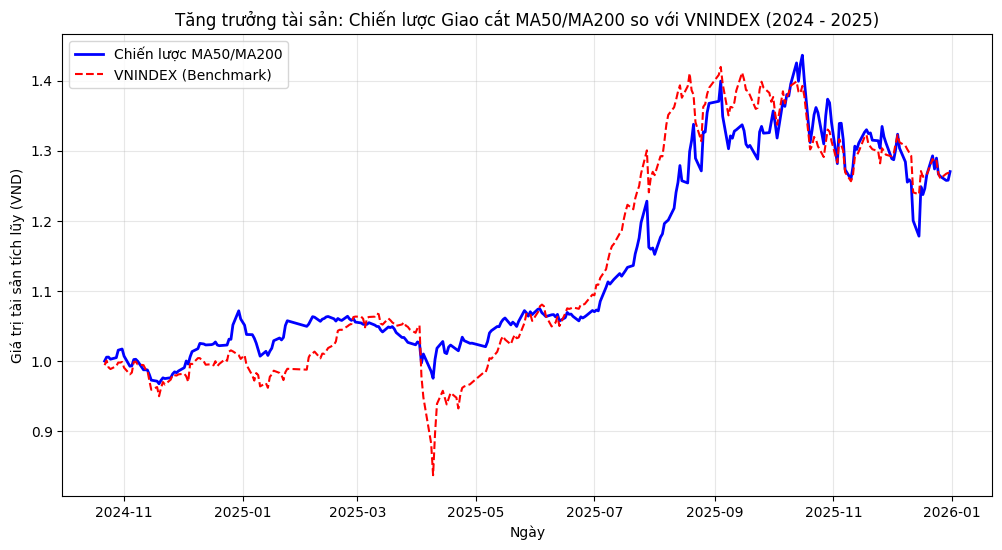

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Tính toán các chỉ báo kỹ thuật cần thiết trực tiếp trên tập TEST cho 5 cổ phiếu đã chọn
# Sử dụng hàm add_ta_indicators đã viết ở trên để tính SMA50 và SMA200 cho tập test
stock_test_ta = add_ta_indicators(df_test[df_test["ticker"].isin(selected_5_tickers)])

# Lọc lấy dữ liệu hợp lệ (bỏ qua các dòng trống của giai đoạn tính toán rolling ban đầu)
test_signals_ma = stock_test_ta.dropna(subset=["SMA50", "SMA200"]).copy()

# Xác định tín hiệu dựa trên việc MA50 giao cắt lên trên MA200
test_signals_ma["MA_Signal"] = (test_signals_ma["SMA50"] > test_signals_ma["SMA200"]).astype(int)

# Tránh look-ahead bias bằng cách dịch chuyển tín hiệu (shift) đi 1 ngày
test_signals_ma["MA_Position"] = test_signals_ma.groupby("ticker")["MA_Signal"].shift(1).fillna(0)

# Tính toán lợi suất chiến lược cho từng cổ phiếu
test_signals_ma["Strategy_Return"] = test_signals_ma["MA_Position"] * test_signals_ma["return"]

# 2. Tạo ma trận lợi suất chiến lược giữa các cổ phiếu
strategy_returns_pivot = test_signals_ma.pivot(
    index="date",
    columns="ticker",
    values="Strategy_Return"
).dropna()

# 3. Tính toán hiệu suất tổng hợp cho danh mục Equal Weight áp dụng tín hiệu MA
ma_portfolio_returns = pd.DataFrame(index=strategy_returns_pivot.index)
ma_portfolio_returns["MA_Crossover_Strategy"] = strategy_returns_pivot.mean(axis=1)

# Căn khớp ngày với VNINDEX (vni_test_daily)
common_dates_ma = ma_portfolio_returns.index.intersection(vni_test_daily.index)
ma_portfolio_returns = ma_portfolio_returns.loc[common_dates_ma].copy()
ma_portfolio_returns["VNINDEX"] = vni_test_daily.loc[common_dates_ma]

# 4. Đánh giá chi tiết hiệu suất
performance_ma_strategy = pd.DataFrame({
    name: performance_stats(ma_portfolio_returns[name])
    for name in ma_portfolio_returns.columns
}).T

print("=== KẾT QUẢ KIỂM ĐỊNH CHIẾN LƯỢC MUA/BÁN THEO MA50/MA200 TRÊN TẬP TEST (2024 - 2025) ===")
display(performance_ma_strategy.style.format({
    "Cumulative Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.4f}",
    "Max Drawdown": "{:.2%}"
}))

# 5. Vẽ biểu đồ so sánh sự tăng trưởng tài sản
growth_ma = (1 + ma_portfolio_returns).cumprod()
plt.figure(figsize=(12, 6))
plt.plot(growth_ma.index, growth_ma["MA_Crossover_Strategy"], label="Chiến lược MA50/MA200", color="blue", lw=2)
plt.plot(growth_ma.index, growth_ma["VNINDEX"], label="VNINDEX (Benchmark)", color="red", linestyle="--", lw=1.5)
plt.title("Tăng trưởng tài sản: Chiến lược Giao cắt MA50/MA200 so với VNINDEX (2024 - 2025)")
plt.xlabel("Ngày")
plt.ylabel("Giá trị tài sản tích lũy (VND)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()